# Лабораторная работа 5-6: Сравнительный анализ методов кластеризации 

#### __1. Загрузка данных и подготовка__

Загрузим подготовленный датасет из 3 лабораторной работы.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.manifold import TSNE
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Настройка стилей графиков
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")
plt.rcParams['figure.figsize'] = (12, 8)

# Настройка отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Загрузка данных
df = pd.read_csv('Data\Dataset_3laba.csv', sep = ',', encoding='latin1')

features = ['memory_variability', 'max_cpus', 'max_memory', 'page_cache_memory', 'cycles_per_instruction_norm']

X = df[features].copy().dropna()

# Масштабирование
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA для визуализации
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_scaled)

print(f"Размер данных: {X_scaled.shape}")
print(f"Доля объясненной дисперсии PCA: {pca.explained_variance_ratio_.sum():.2%}")

print("\nПервые 5 строк:")
df.head()


Размер данных: (498, 5)
Доля объясненной дисперсии PCA: 100.00%

Первые 5 строк:


,duration,instance_index,memory_variability,avg_cpus,avg_memory,max_cpus,max_memory,page_cache_memory,cycles_per_instruction_norm,memory_accesses_per_instruction_std
0,0.3,111,2.045086,0.008392,0.009476,0.047913,0.019379,0.003220,0.063542,-0.788944
1,0.3,111,1.012154,0.027100,0.027618,0.073608,0.027954,0.001808,0.063542,-0.788944
2,0.3,111,1.547122,0.024933,0.012466,0.117676,0.019287,0.002392,0.087088,-0.245127
3,0.3,111,1.763230,0.019135,0.010956,0.120972,0.019318,0.001934,0.095564,-0.217250
4,0.3,111,2.039740,0.001163,0.000959,0.011063,0.001957,0.000813,0.063542,-0.788944


#### __1. Иерархическая кластеризация__
Построение дендрограмм для всех комбинаций

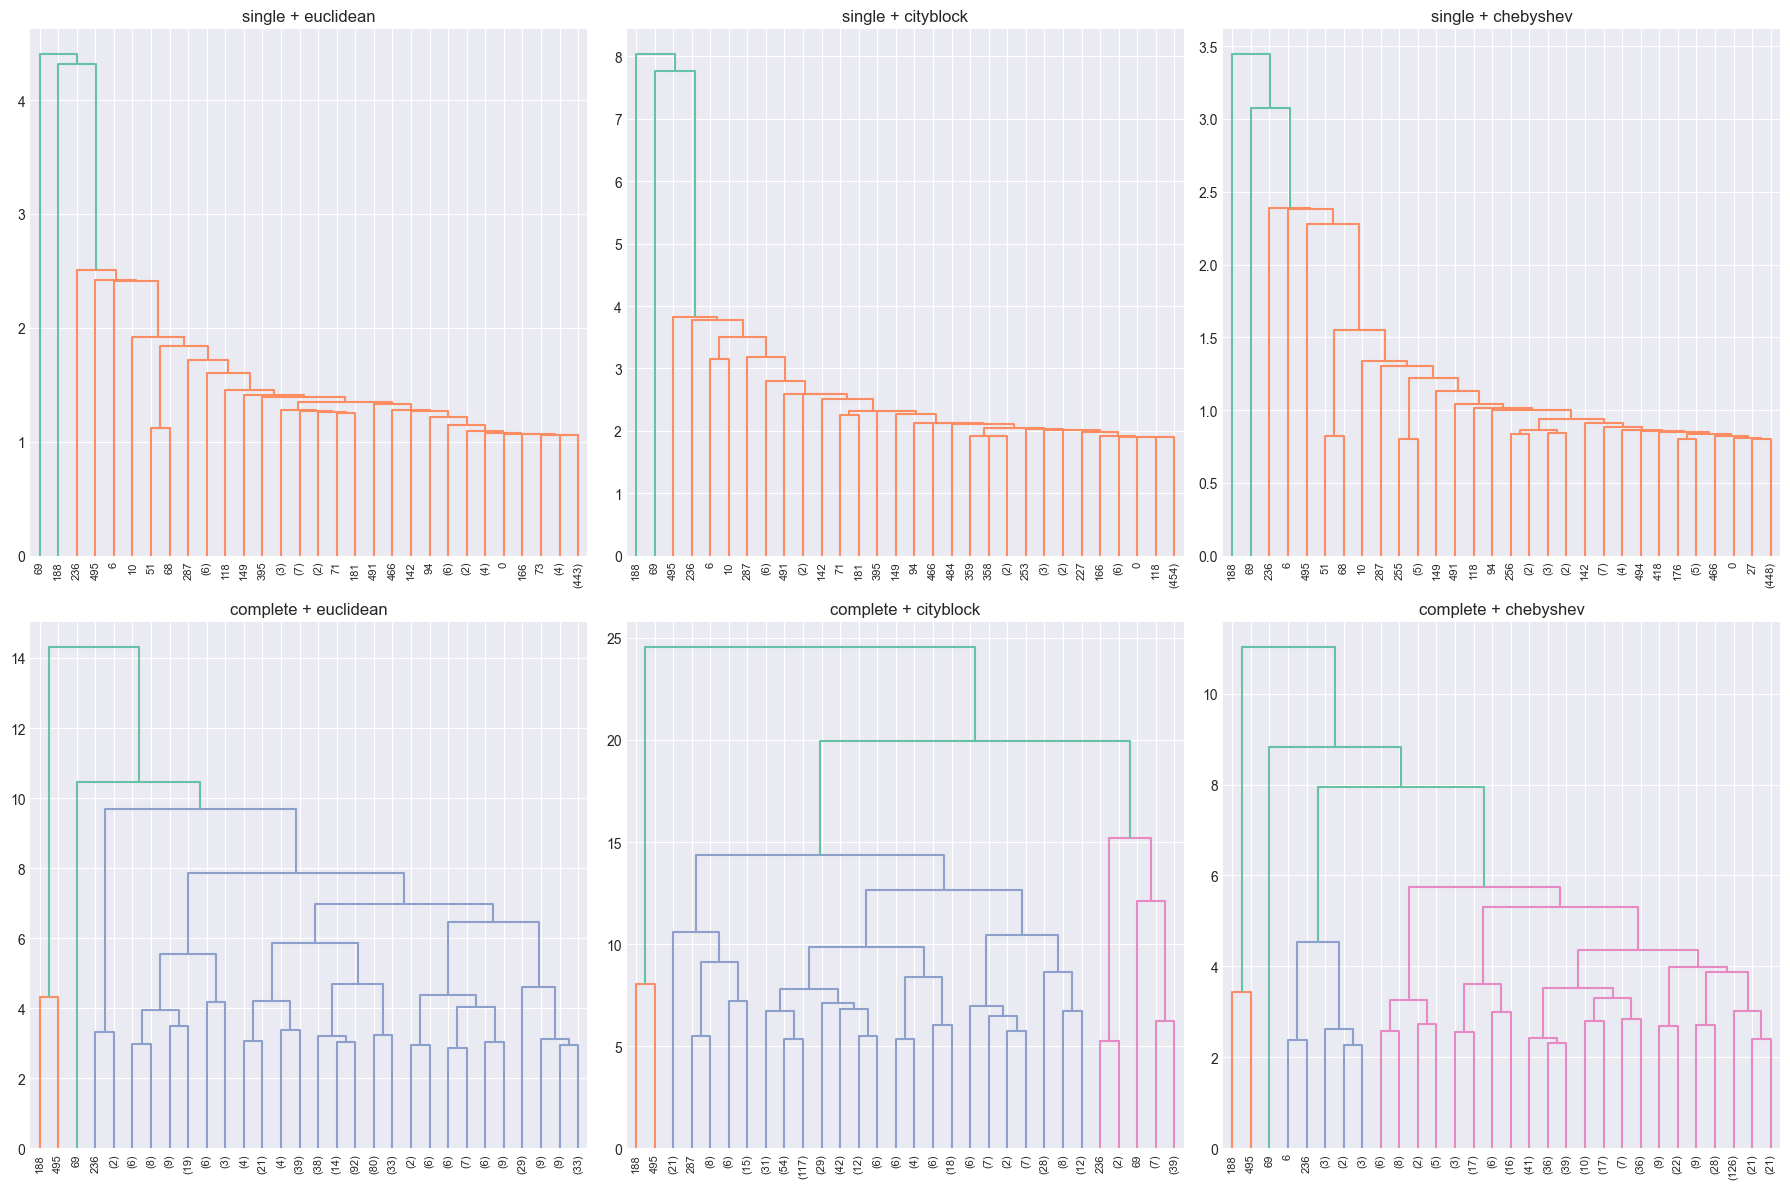

In [9]:
# Параметры для анализа
linkage_methods = ['single', 'complete']            # одиночная связь (single), полная связь (complete)
metrics = ['euclidean', 'cityblock', 'chebyshev']   # Евклидова (euclidean), Манхэттенская (cityblock), Чебышева (chebyshev)

manual_k = {
    'single_euclidean': 2,      #   2
    'single_cityblock': 2,      #   2
    'single_chebyshev': 2,      #   2
    'complete_euclidean': 6,    #   3
    'complete_cityblock': 3,    #   3
    'complete_chebyshev': 6,    #   2
}

USE_MANUAL_K = True

results_hierarchical = {}

for linkage_method in linkage_methods:
    for metric in metrics:
        Z = linkage(X_scaled, method=linkage_method, metric=metric)

        key = f"{linkage_method}_{metric}"

        if USE_MANUAL_K:
            k = manual_k[key]
            model = AgglomerativeClustering(n_clusters=k, linkage=linkage_method, metric=metric)
            labels = model.fit_predict(X_scaled)
            if len(set(labels)) > 1:
                score = silhouette_score(X_scaled, labels, metric=metric)
            else:
                score = -1

            results_hierarchical[key] = {
                'best_k': k,
                'silhouette': score
            }

        else:
            best_score = -1
            best_k = 2
            for k in range(2, 8):
                model = AgglomerativeClustering(n_clusters=k, linkage=linkage_method, metric=metric)
                labels = model.fit_predict(X_scaled)
                if len(set(labels)) > 1:
                    score = silhouette_score(X_scaled, labels, metric=metric)
                    print(f"  k={k}: Silhouette = {score:.4f}")
                    if score > best_score:
                        best_score = score
                        best_k = k

            results_hierarchical[key] = {
                'best_k': best_k,
                'silhouette': best_score
            }
            print(f"\nРекомендуемое k: {best_k} (silhouette = {best_score:.4f})")
# Создание подграфиков 2x3
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

plot_idx = 0

for linkage_method in linkage_methods:
    for metric in metrics:
        # Построение матрицы связей и дендрограммы
        Z = linkage(X_scaled, method=linkage_method, metric=metric)
        dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90,
                   leaf_font_size=8, ax=axes[plot_idx])
        axes[plot_idx].set_title(f'{linkage_method} + {metric}')
        plot_idx += 1

plt.tight_layout()
plt.show()

Выполнение разбиения на оптимальное k и визуализация


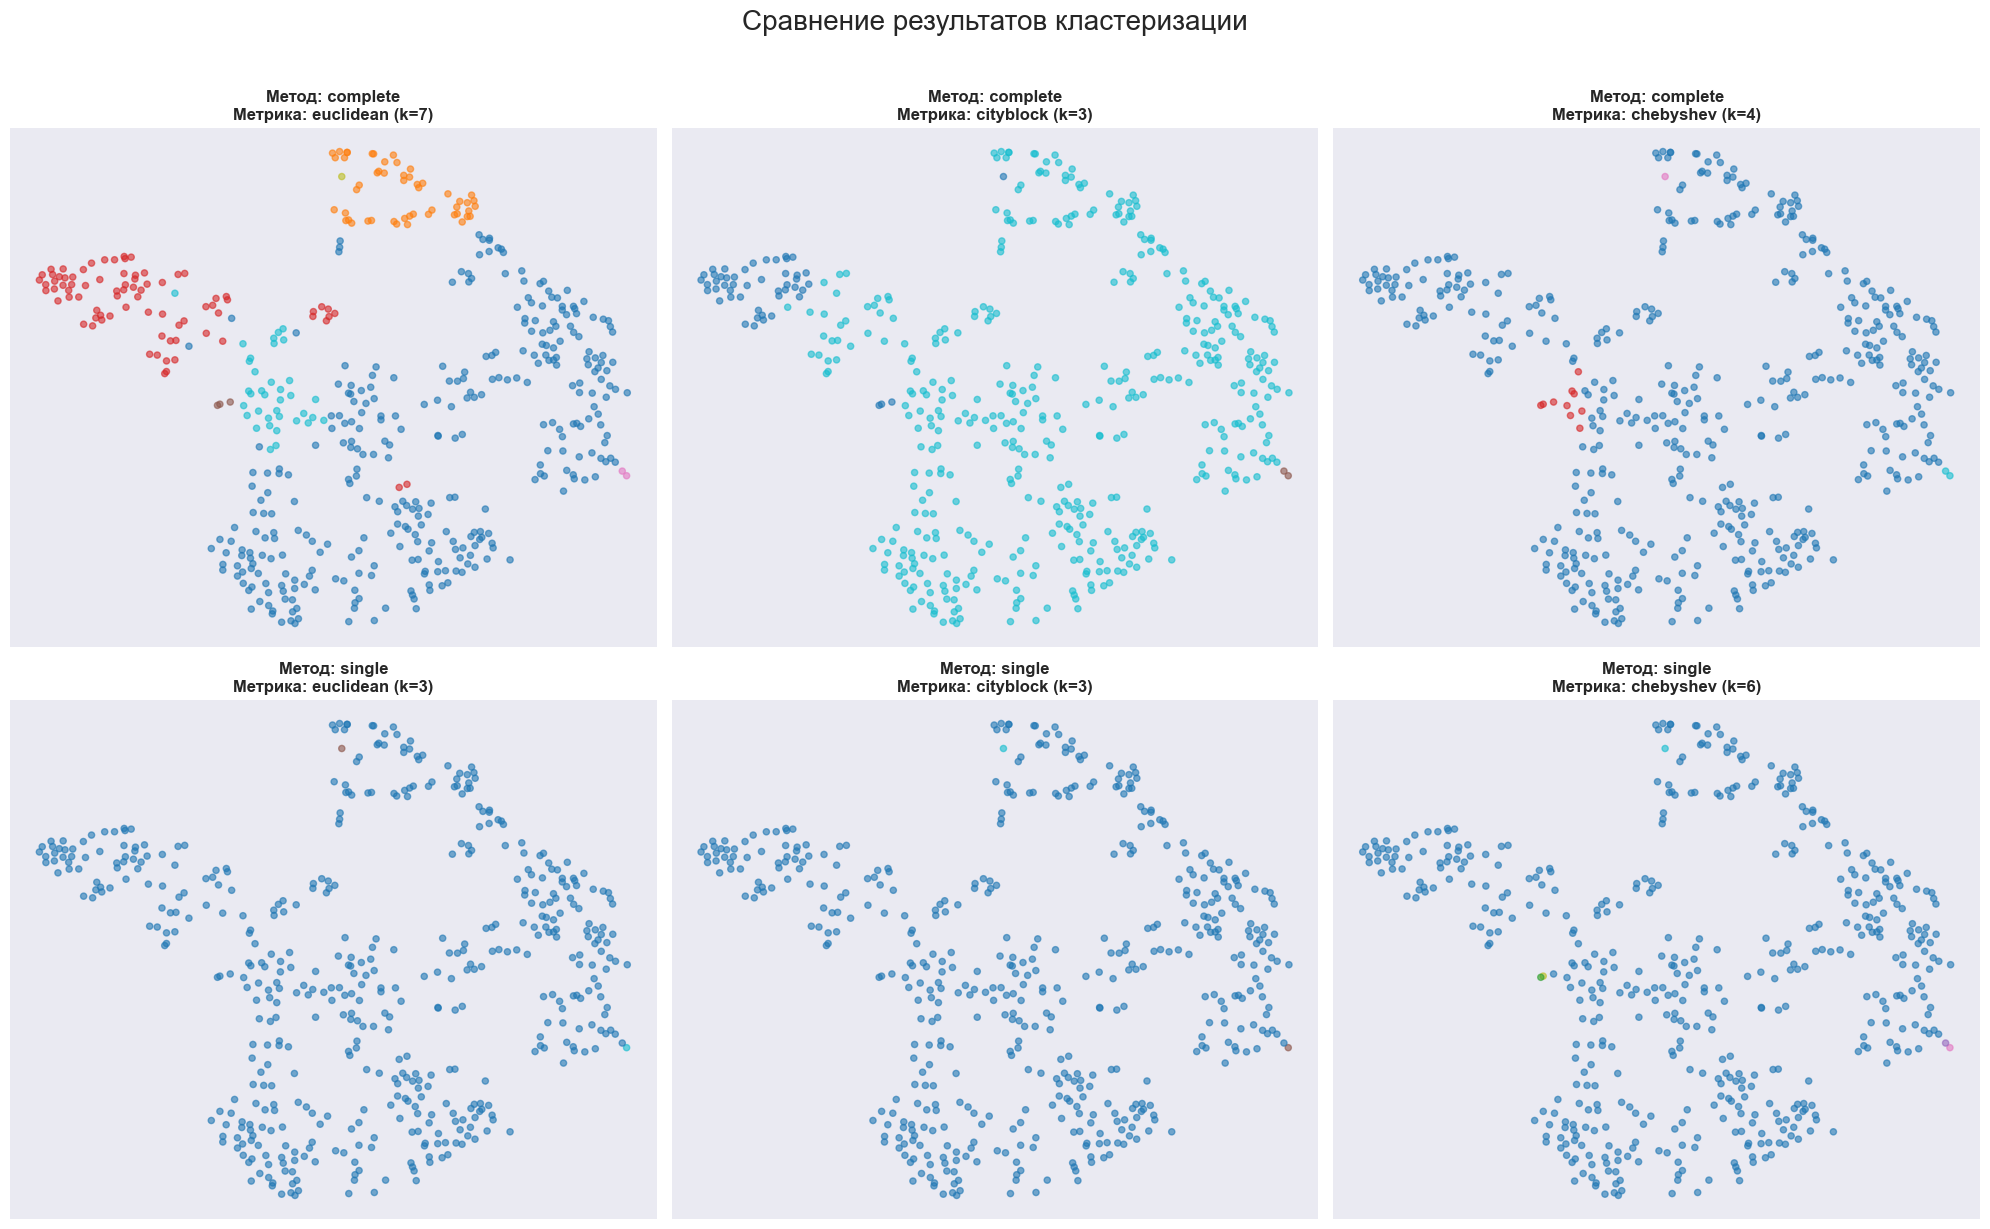

In [10]:
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.manifold import TSNE

manual_k = {
    'single_euclidean': 3,
    'single_cityblock': 3,
    'single_chebyshev': 6,
    'complete_euclidean': 7,
    'complete_cityblock': 3,
    'complete_chebyshev': 4
}


tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)


fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()


sorted_configs = sorted(manual_k.keys(), key=lambda x: x.startswith('complete'), reverse=True)

for i, config in enumerate(sorted_configs):
    method, metric = config.split('_')
    k = manual_k[config]

    # Обучаем модель
    model = AgglomerativeClustering(n_clusters=k, linkage=method, metric=metric)
    labels = model.fit_predict(X_scaled)

    # Отрисовка
    ax = axes[i]
    scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],
                         c=labels,
                         cmap='tab10',
                         s=20,
                         alpha=0.6)

    ax.set_title(f"Метод: {method}\nМетрика: {metric} (k={k})", fontsize=12, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])


plt.suptitle("Сравнение результатов кластеризации", fontsize=20, y=1.02)
plt.tight_layout()
plt.show()


Расчет коэффициента силуэта для каждого разбиения (сводная таблица)

In [11]:
print("\n" + "="*70)
print("Сводная таблица результатов иерархической кластеризации")
print("="*70)
print(f"{'Метод связи':<12} {'Метрика':<12} {'Оптимальное k':<15} {'Silhouette':<12}")
print("-"*70)

for config, data in results_hierarchical.items():
    method, metric = config.split('_')
    print(f"{method:<12} {metric:<12} {data['best_k']:<15} {data['silhouette']:.4f}")


Сводная таблица результатов иерархической кластеризации
Метод связи  Метрика      Оптимальное k   Silhouette  
----------------------------------------------------------------------
single       euclidean    3               0.6573
single       cityblock    3               0.5830
single       chebyshev    6               0.6034
complete     euclidean    7               0.3128
complete     cityblock    3               0.3916
complete     chebyshev    4               0.5122


#### __2. Алгоритм k-средних (k-means)__

Метрики расстояния: Евклидова (используется по умолчанию), Манхэттенская (для сравнения). Используя метод локтя (Elbow method), определим оптимальное количество 
кластеров `k`.


k-means с метрикой: euclidean
Оптимальное k: 2

k-means с метрикой: cityblock
Оптимальное k: 2


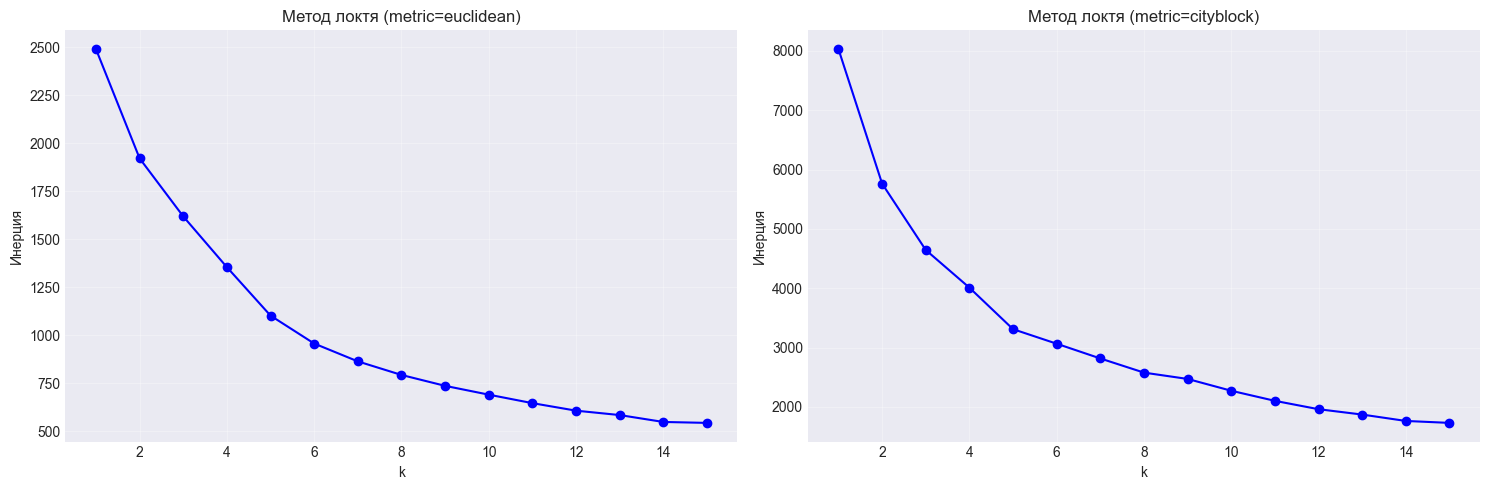

In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import pairwise_distances

def elbow_method_kmeans(X_scaled, max_k=15, metric='euclidean'):
    """Вычисление инерции для метода локтя"""
    inertias = []
    k_range = range(1, max_k + 1)

    if metric == 'euclidean':
        for k in k_range:
            kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
            kmeans.fit(X_scaled)
            inertias.append(kmeans.inertia_)
    else:
        for k in k_range:
            kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
            kmeans.fit(X_scaled)
            distances = pairwise_distances(X_scaled, kmeans.cluster_centers_, metric=metric)
            inertia = np.sum(np.min(distances, axis=1) ** 2)
            inertias.append(inertia)

    return k_range, inertias

# Анализ для разных метрик
metrics_kmeans = ['euclidean', 'cityblock']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
optimal_k_values = {}

for idx, metric in enumerate(metrics_kmeans):
    print(f"\n{'='*50}")
    print(f"k-means с метрикой: {metric}")
    print('='*50)

    k_range, inertias = elbow_method_kmeans(X_scaled, max_k=15, metric=metric)

    # Построение графика
    axes[idx].plot(k_range, inertias, 'bo-')
    axes[idx].set_title(f'Метод локтя (metric={metric})')
    axes[idx].set_xlabel('k')
    axes[idx].set_ylabel('Инерция')
    axes[idx].grid(True, alpha=0.3)

    # Нахождение точки перегиба (оптимального k)
    diffs = np.diff(inertias)
    diffs2 = np.diff(diffs)
    optimal_k = np.argmax(diffs2) + 2
    optimal_k = max(2, min(optimal_k, 10))

    optimal_k_values[metric] = optimal_k
    print(f"Оптимальное k: {optimal_k}")

plt.tight_layout()
plt.show()

Выполним кластеризацию алгоритмом k-means++  для найденного `k` с разными 
метриками. 

In [20]:
# Выполните кластеризацию алгоритмом k-means++ для найденного k с разными метриками

kmeans_results = {}

for metric in metrics_kmeans:
    print(f"\n{'='*50}")
    print(f"k-means++ с метрикой: {metric}")
    optimal_k = optimal_k_values[metric]

    # Кластеризация с найденным k
    if metric == 'euclidean':
        kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
        labels = kmeans.fit_predict(X_scaled)
    else:
        kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
        kmeans.fit(X_scaled)
        labels = kmeans.labels_

    # Оценка качества
    if len(set(labels)) > 1:
        silhouette = silhouette_score(X_scaled, labels, metric=metric)
        print(f"Коэффициент силуэта: {silhouette:.4f}")
        kmeans_results[metric] = {'k': optimal_k, 'silhouette': silhouette, 'labels': labels}
    else:
        print("Только один кластер!")

# Вывод всех результатов
print(f"\n{'-'*50}")
print("Результаты:")
for metric, result in kmeans_results.items():
    print(f"{metric}: k={result['k']}, silhouette={result['silhouette']:.4f}")


k-means++ с метрикой: euclidean
Коэффициент силуэта: 0.3281

k-means++ с метрикой: cityblock
Коэффициент силуэта: 0.3584

--------------------------------------------------
Результаты:
euclidean: k=2, silhouette=0.3281
cityblock: k=2, silhouette=0.3584


Визуализация результатов на плоскости.

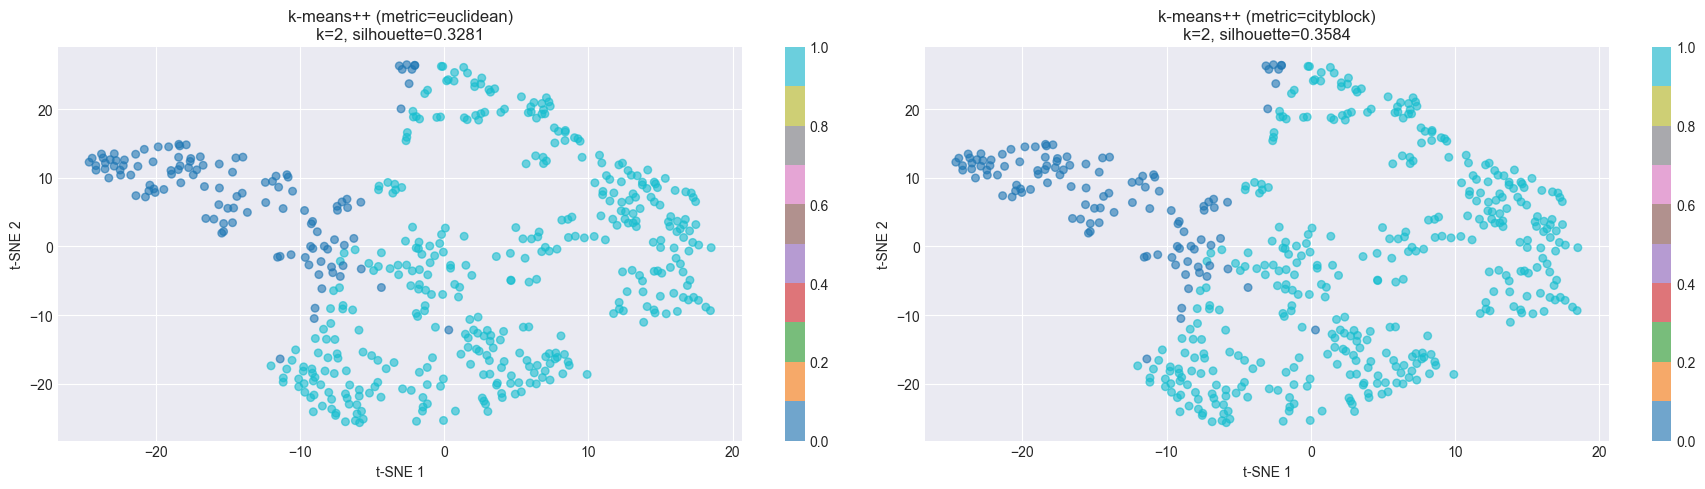

КОЭФ.Т СИЛУЭТА ДЛЯ КАЖДОГО РАЗБИЕНИЯ:
-----------------------------------
Метрика         k     Silhouette
-----------------------------------
euclidean       2     0.3281
cityblock       2     0.3584


In [21]:
# t-SNE для визуализации
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# Визуализация результатов для каждой метрики
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

for idx, (metric, result) in enumerate(kmeans_results.items()):
    # t-SNE визуализация
    scatter = axes[idx].scatter(X_tsne[:, 0], X_tsne[:, 1],
                                c=result['labels'], cmap='tab10', alpha=0.6, s=30)
    axes[idx].set_title(f'k-means++ (metric={metric})\nk={result["k"]}, silhouette={result["silhouette"]:.4f}')
    axes[idx].set_xlabel('t-SNE 1')
    axes[idx].set_ylabel('t-SNE 2')
    plt.colorbar(scatter, ax=axes[idx])

plt.tight_layout()
plt.show()

# Дополнительно: вывод всех силуэтов в таблицу
print("КОЭФ.Т СИЛУЭТА ДЛЯ КАЖДОГО РАЗБИЕНИЯ:")
print("-"*35)
print(f"{'Метрика':<15} {'k':<5} {'Silhouette':<10}")
print("-"*35)
for metric, result in kmeans_results.items():
    print(f"{metric:<15} {result['k']:<5} {result['silhouette']:.4f}")


#### __3. Плотностной алгоритм DBSCAN__

Метрики расстояния: Евклидова, Манхэттенская. Подберем параметры `eps` (радиус окрестности) и `MinPts` (минимальное количество 
точек в окрестности) для каждой метрики расстояния, чтобы получить осмысленное разбиение. 

ПОДБОР ПАРАМЕТРОВ DBSCAN

DBSCAN с метрикой: euclidean


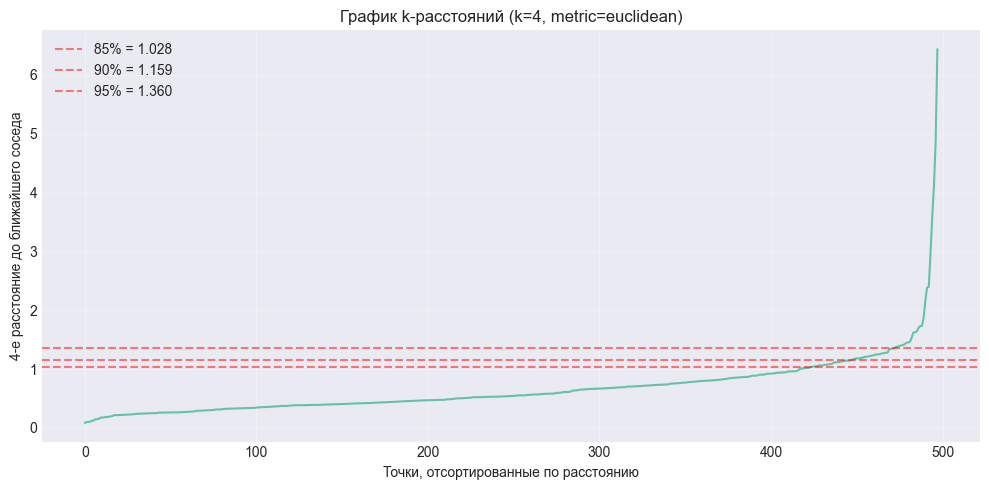

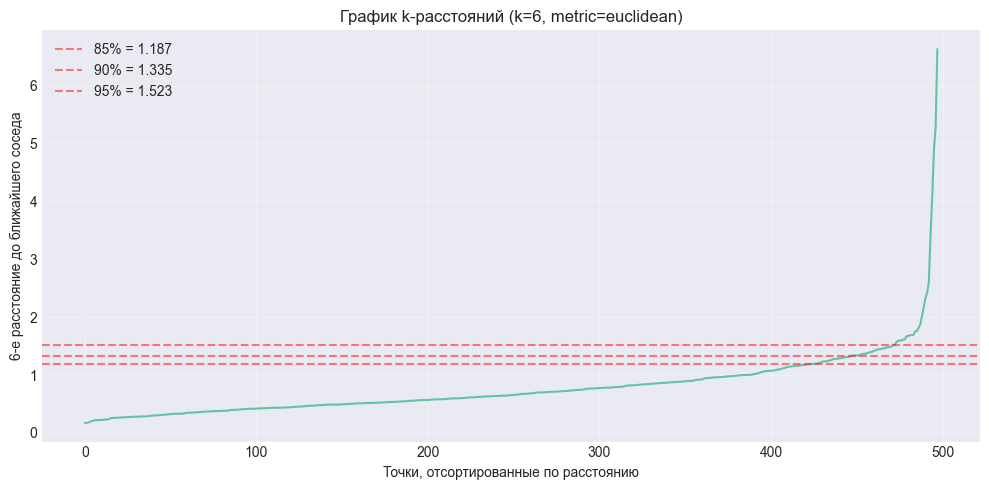

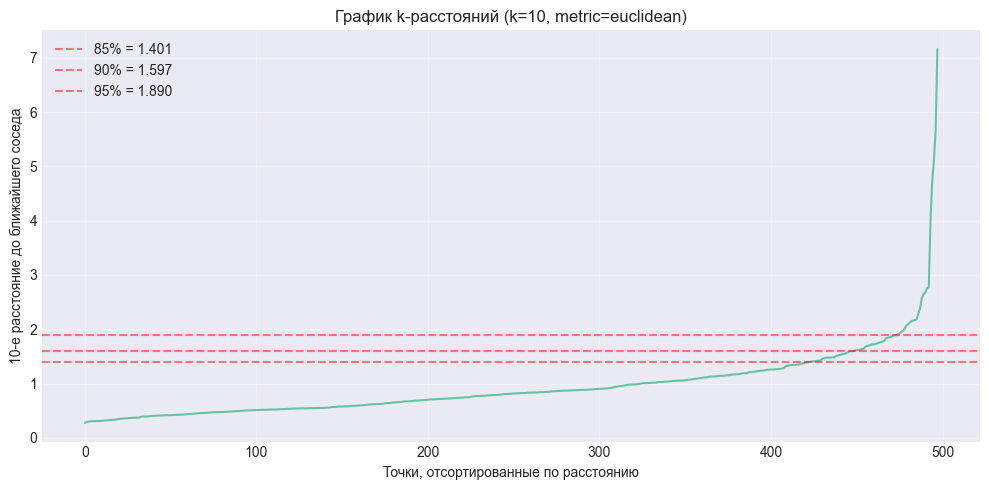


✓ Найдены оптимальные параметры:
  min_pts = 20
  eps = 1.0232 (перцентиль: 50%)
  Количество кластеров: 2
  Количество шумовых точек: 148 (29.7%)
  Коэффициент силуэта (без шума): 0.5002

DBSCAN с метрикой: cityblock


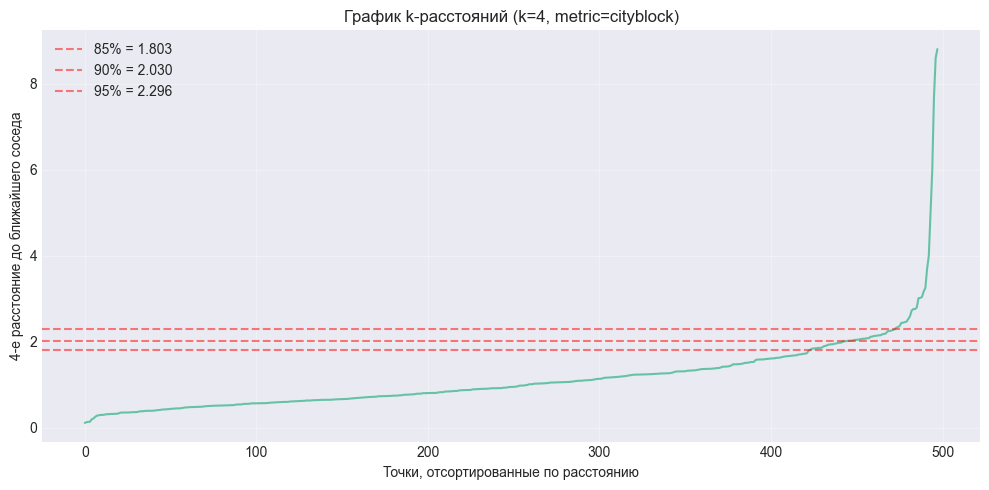

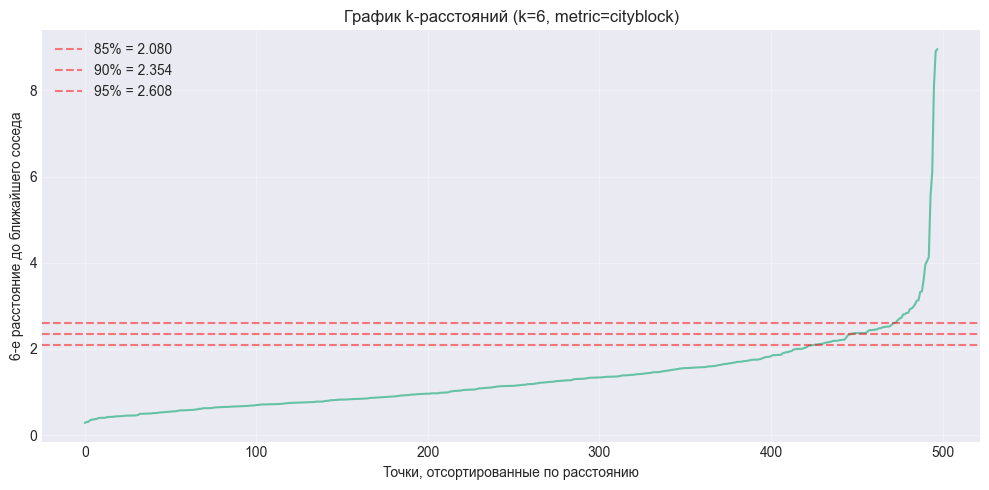

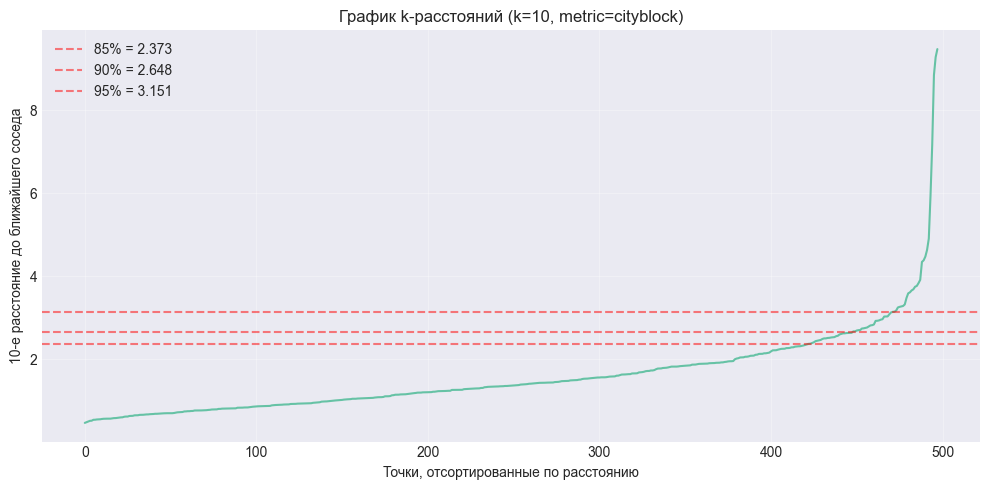


✓ Найдены оптимальные параметры:
  min_pts = 6
  eps = 1.1386 (перцентиль: 50%)
  Количество кластеров: 2
  Количество шумовых точек: 184 (36.9%)
  Коэффициент силуэта (без шума): 0.5595


In [16]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

def find_optimal_dbscan_params(X_scaled, metric='euclidean'):
    """Поиск оптимальных параметров eps и min_pts для DBSCAN"""
    best_results = []
    min_pts_range = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20]

    for min_pts in min_pts_range:
        if min_pts >= len(X_scaled):
            continue

        # График k-расстояний
        neigh = NearestNeighbors(n_neighbors=min_pts, metric=metric)
        neigh.fit(X_scaled)
        distances, _ = neigh.kneighbors(X_scaled)
        k_distances = np.sort(distances[:, -1])

        # Пробуем разные eps на основе квантилей
        percentiles = [50, 60, 70, 75, 80, 85, 90, 92, 95, 97, 98, 99]

        for p in percentiles:
            eps = np.percentile(k_distances, p)
            if eps < 0.01:
                continue

            dbscan = DBSCAN(eps=eps, min_samples=min_pts, metric=metric)
            labels = dbscan.fit_predict(X_scaled)

            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = list(labels).count(-1)
            noise_ratio = n_noise / len(labels)

            if n_clusters >= 2 and n_clusters <= 15 and noise_ratio <= 0.6:
                mask = labels != -1
                if mask.sum() > 10 and len(set(labels[mask])) >= 2:
                    try:
                        silhouette = silhouette_score(X_scaled[mask], labels[mask], metric=metric)
                        best_results.append({
                            'min_pts': min_pts,
                            'eps': eps,
                            'n_clusters': n_clusters,
                            'n_noise': n_noise,
                            'noise_ratio': noise_ratio,
                            'silhouette': silhouette,
                            'labels': labels,
                            'percentile': p
                        })
                    except Exception:
                        pass

    if best_results:
        best_results.sort(key=lambda x: x['silhouette'], reverse=True)
        return best_results[0]
    return None

def plot_k_distance_graph(X_scaled, metric='euclidean', min_pts=4):
    """Построение графика k-расстояний"""
    neigh = NearestNeighbors(n_neighbors=min_pts, metric=metric)
    neigh.fit(X_scaled)
    distances, _ = neigh.kneighbors(X_scaled)
    k_distances = np.sort(distances[:, -1])

    plt.figure(figsize=(10, 5))
    plt.plot(k_distances)
    plt.title(f'График k-расстояний (k={min_pts}, metric={metric})')
    plt.xlabel('Точки, отсортированные по расстоянию')
    plt.ylabel(f'{min_pts}-е расстояние до ближайшего соседа')
    plt.grid(True, alpha=0.3)

    for percentile in [85, 90, 95]:
        eps_val = np.percentile(k_distances, percentile)
        plt.axhline(y=eps_val, color='r', linestyle='--', alpha=0.5,
                   label=f'{percentile}% = {eps_val:.3f}')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return k_distances

metrics_dbscan = ['euclidean', 'cityblock']
dbscan_results = {}

print("="*60)
print("ПОДБОР ПАРАМЕТРОВ DBSCAN")
print("="*60)

for metric in metrics_dbscan:
    print(f"\n{'='*50}")
    print(f"DBSCAN с метрикой: {metric}")
    print('='*50)

    # Графики k-расстояний для разных k
    for k in [4, 6, 10]:
        plot_k_distance_graph(X_scaled, metric=metric, min_pts=k)

    # Поиск оптимальных параметров
    best = find_optimal_dbscan_params(X_scaled, metric=metric)

    if best:
        print(f"\n✓ Найдены оптимальные параметры:")
        print(f"  min_pts = {best['min_pts']}")
        print(f"  eps = {best['eps']:.4f} (перцентиль: {best['percentile']}%)")
        print(f"  Количество кластеров: {best['n_clusters']}")
        print(f"  Количество шумовых точек: {best['n_noise']} ({best['noise_ratio']:.1%})")
        print(f"  Коэффициент силуэта (без шума): {best['silhouette']:.4f}")
        dbscan_results[metric] = best
    else:
        print(f"\n✗ Не удалось найти подходящие параметры для метрики {metric}")

Визуализация результатов DBSCAN

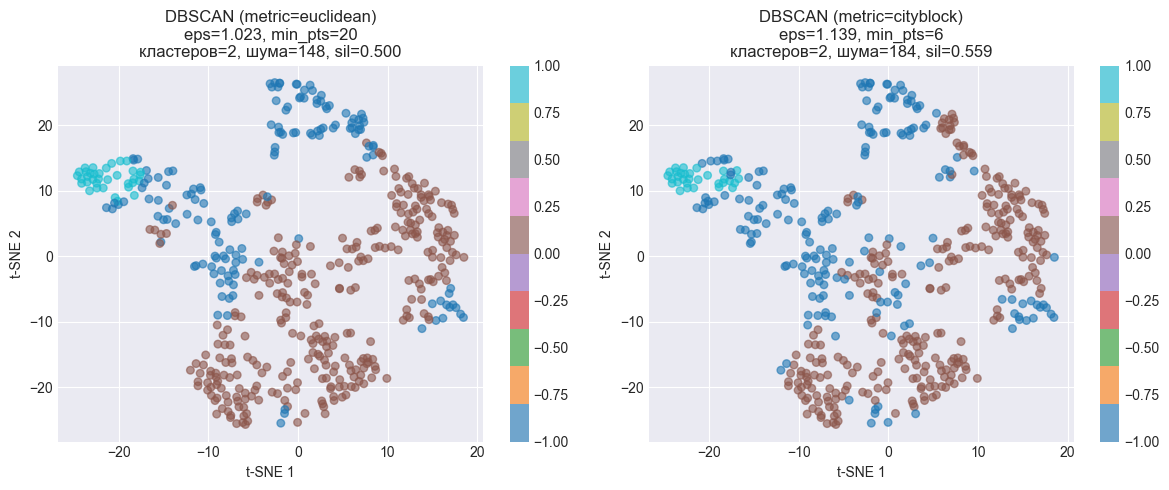

In [17]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# Визуализация результатов DBSCAN для каждой метрики
if dbscan_results:
    fig, axes = plt.subplots(1, len(dbscan_results), figsize=(6*len(dbscan_results), 5))
    if len(dbscan_results) == 1:
        axes = [axes]

    for idx, (metric, result) in enumerate(dbscan_results.items()):
        labels = result['labels']
        n_clusters = result['n_clusters']
        n_noise = result['n_noise']
        # Шумовые точки (метка -1) выделяем другим цветом и маркером
        scatter = axes[idx].scatter(X_tsne[:, 0], X_tsne[:, 1],
                                    c=labels, cmap='tab10', alpha=0.6, s=30)
        axes[idx].set_title(f'DBSCAN (metric={metric})\neps={result["eps"]:.3f}, min_pts={result["min_pts"]}\n'
                           f'кластеров={n_clusters}, шума={n_noise}, sil={result["silhouette"]:.3f}')
        axes[idx].set_xlabel('t-SNE 1')
        axes[idx].set_ylabel('t-SNE 2')
        plt.colorbar(scatter, ax=axes[idx])
    plt.tight_layout()
    plt.show()



Рассчет коэффициента силуэта


In [18]:
for metric, result in dbscan_results.items():
    labels = result['labels']

    # Исключаем шумовые точки (метка -1)
    mask = labels != -1
    X_filtered = X_scaled[mask]
    labels_filtered = labels[mask]

    n_clusters = len(set(labels_filtered))
    n_noise = (~mask).sum()

    print(f"\n{metric}:")
    print(f"  Всего точек: {len(labels)}")
    print(f"  Точек в кластерах: {len(X_filtered)}")
    print(f"  Количество кластеров: {n_clusters}")



euclidean:
  Всего точек: 498
  Точек в кластерах: 350
  Количество кластеров: 2

cityblock:
  Всего точек: 498
  Точек в кластерах: 314
  Количество кластеров: 2


#### __4. Сравнение результатов__

In [22]:
import pandas as pd

# Сбор данных для сводной таблицы
comparison_data = []

print("\n" + "-"*80)
print("Результаты иерархической кластеризации")
for config, result in results_hierarchical.items():
    linkage_method, metric = config.split('_')
    comparison_data.append({
        'Алгоритм': 'Иерархическая',
        'Метрика': metric,
        'Метод связи': linkage_method,
        'k (кластеры)': result['best_k'],
        'Шум (DBSCAN)': '-',
        'Silhouette': result['silhouette'],
        #'Визуальная оценка': 'Хорошо разделимые кластеры' if result['silhouette'] > 0.5 else 'Среднее разделение'
    })
    print(f"Иерархическая: {linkage_method}+{metric} → k={result['best_k']}, sil={result['silhouette']:.4f}")

# 2. K-means++ (kmeans_results)
print("\n" + "-"*80)
print("Результаты K-MEANS++")
for metric, result in kmeans_results.items():
    comparison_data.append({
        'Алгоритм': 'K-means++',
        'Метрика': metric,
        'Метод связи': '-',
        'k (кластеры)': result['k'],
        'Шум (DBSCAN)': '-',
        'Silhouette': result['silhouette'],
        #'Визуальная оценка': 'Хорошо разделимые кластеры' if result['silhouette'] > 0.5 else 'Среднее разделение'
    })
    print(f"K-means++: {metric} → k={result['k']}, sil={result['silhouette']:.4f}")

# 3. DBSCAN (dbscan_results)
print("\n" + "-"*80)
print("Результаты DBSCAN")

for metric, result in dbscan_results.items():
    comparison_data.append({
        'Алгоритм': 'DBSCAN',
        'Метрика': metric,
        'Метод связи': '-',
        'k (кластеры)': f"{result['n_clusters']} (+{result['n_noise']} шума)",
        'Шум (DBSCAN)': result['n_noise'],
        'Silhouette': result['silhouette'],
        #'Визуальная оценка': f" шум {result['noise_ratio']:.1%}"
    })
    print(f"DBSCAN: {metric} → кластеров={result['n_clusters']}, шума={result['n_noise']}, sil={result['silhouette']:.4f}")

# Создание сводной таблицы
df_comparison = pd.DataFrame(comparison_data)

# Сортировка по силуэту (от лучшего к худшему)
df_comparison = df_comparison.sort_values('Silhouette', ascending=False)

# Вывод таблицы
print("\n" + "-"*80)
print("СВОДНАЯ ТАБЛИЦА СРАВНЕНИЯ АЛГОРИТМОВ")
print(df_comparison.to_string(index=False))



--------------------------------------------------------------------------------
Результаты иерархической кластеризации
Иерархическая: single+euclidean → k=3, sil=0.6573
Иерархическая: single+cityblock → k=3, sil=0.5830
Иерархическая: single+chebyshev → k=6, sil=0.6034
Иерархическая: complete+euclidean → k=7, sil=0.3128
Иерархическая: complete+cityblock → k=3, sil=0.3916
Иерархическая: complete+chebyshev → k=4, sil=0.5122

--------------------------------------------------------------------------------
Результаты K-MEANS++
K-means++: euclidean → k=2, sil=0.3281
K-means++: cityblock → k=2, sil=0.3584

--------------------------------------------------------------------------------
Результаты DBSCAN
DBSCAN: euclidean → кластеров=2, шума=148, sil=0.5002
DBSCAN: cityblock → кластеров=2, шума=184, sil=0.5595

--------------------------------------------------------------------------------
СВОДНАЯ ТАБЛИЦА СРАВНЕНИЯ АЛГОРИТМОВ
     Алгоритм   Метрика Метод связи  k (кластеры) Шум (DBSCAN)  S

#### __Вариант А. Мягкая (нечеткая) кластеризация__

Реализуем алгоритм  Fuzzy C-Means (FCM) .

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

def fuzzy_c_means(X, c, m=2.0, max_iter=100, error=1e-5, metric='euclidean', random_state=42):
    
    np.random.seed(random_state)
    n = X.shape[0]

    u = np.random.rand(n, c)
    u = u / u.sum(axis=1, keepdims=True)  

    history = []

    for iteration in range(max_iter):
        u_old = u.copy()

        
        um = u ** m  
        centers = (um.T @ X) / um.T.sum(axis=1, keepdims=True)  

        distances = np.zeros((n, c))
        for k in range(c):
            if metric == 'euclidean':
                distances[:, k] = np.sqrt(np.sum((X - centers[k]) ** 2, axis=1))
            elif metric == 'cityblock':
                distances[:, k] = np.sum(np.abs(X - centers[k]), axis=1)
            elif metric == 'chebyshev':
                distances[:, k] = np.max(np.abs(X - centers[k]), axis=1)
            else:
                distances[:, k] = np.sqrt(np.sum((X - centers[k]) ** 2, axis=1))

        distances = np.maximum(distances, 1e-10)

        exponent = 2.0 / (m - 1.0)  # показатель степени в формуле FCM
        inv_dist = 1.0 / distances
        u_new = inv_dist ** exponent
        u_new = u_new / u_new.sum(axis=1, keepdims=True)

        diff = np.linalg.norm(u_new - u_old)
        history.append(diff)
        u = u_new

        if diff < error:
            print(f"    Сходимость достигнута на итерации {iteration + 1}, diff = {diff:.6f}")
            break

    if iteration == max_iter - 1:
        print(f"    Достигнуто максимальное число итераций ({max_iter}), diff = {diff:.6f}")

    return u, centers, history

Выполним кластеризацию с разными значениями параметра нечеткости `m` и разными метриками расстояния 

Оптимальное количество кластеров (из k-means, евклидова метрика): 2

FUZZY C-MEANS: k = 2

Параметр нечёткости m = 1.1
    Сходимость достигнута на итерации 61, diff = 0.000009
  Средняя максимальная степень принадлежности: 0.9768
  Доля точек с max(u) > 0.8: 95.38%

Параметр нечёткости m = 1.5
    Сходимость достигнута на итерации 91, diff = 0.000009
  Средняя максимальная степень принадлежности: 0.8161
  Доля точек с max(u) > 0.8: 58.43%

Параметр нечёткости m = 2.0
    Сходимость достигнута на итерации 58, diff = 0.000008
  Средняя максимальная степень принадлежности: 0.6734
  Доля точек с max(u) > 0.8: 16.27%

Параметр нечёткости m = 3.0
    Достигнуто максимальное число итераций (200), diff = 0.003667
  Средняя максимальная степень принадлежности: 0.5210
  Доля точек с max(u) > 0.8: 0.00%

Параметр нечёткости m = 5.0
    Сходимость достигнута на итерации 44, diff = 0.000009
  Средняя максимальная степень принадлежности: 0.5000
  Доля точек с max(u) > 0.8: 0.00%

Параметр нечёткост

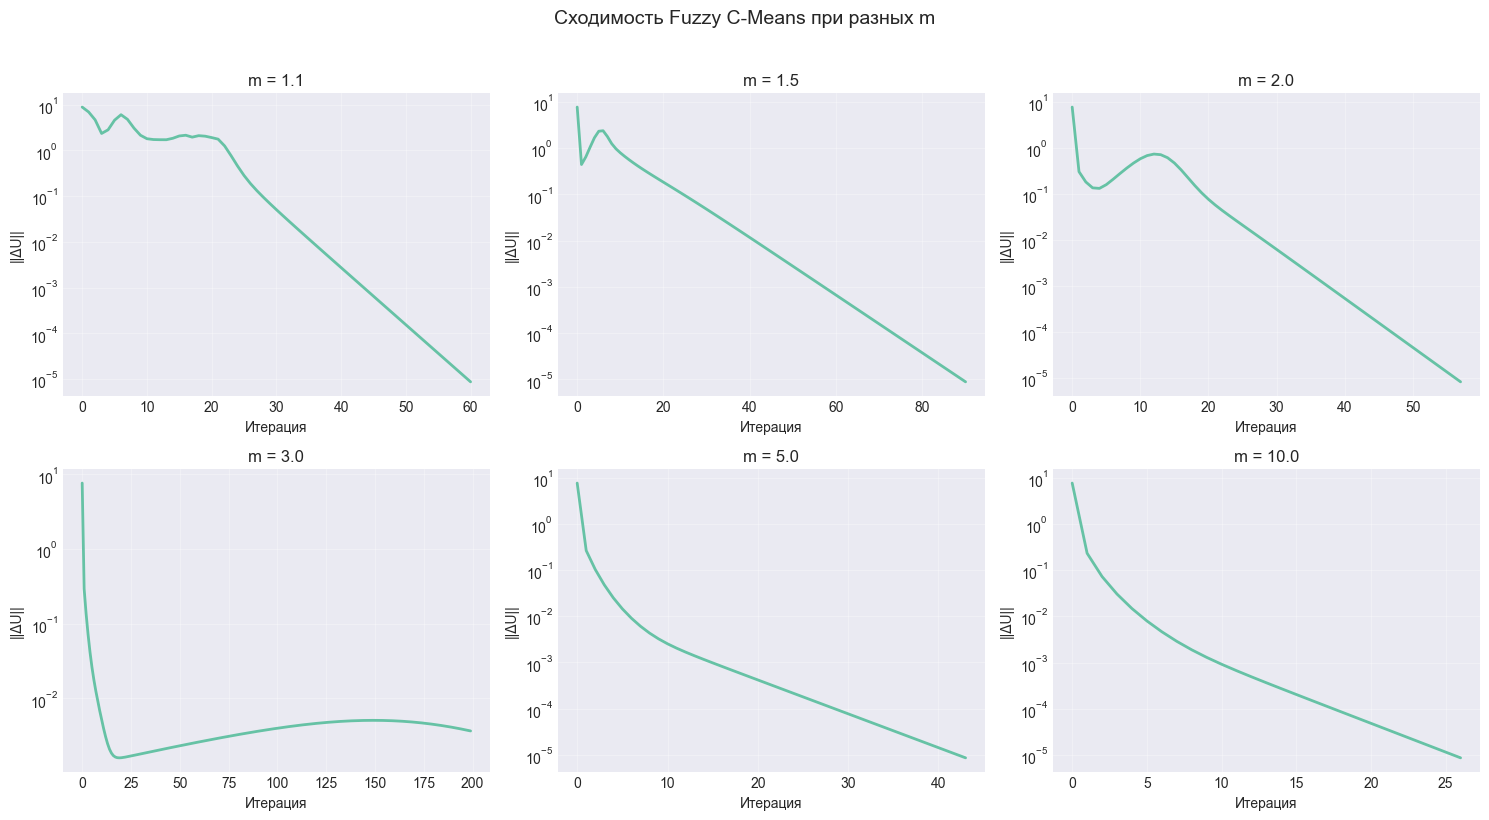

In [24]:
# Определяем k для FCM (возьмём k из k-means для евклидовой метрики)
k_optimal = optimal_k_values.get('euclidean', 3)
print(f"Оптимальное количество кластеров (из k-means, евклидова метрика): {k_optimal}")

# Параметры для исследования
m_values = [1.1, 1.5, 2.0, 3.0, 5.0, 10.0]  # разные степени нечёткости
fcm_results = {}

print("\n" + "=" * 60)
print(f"FUZZY C-MEANS: k = {k_optimal}")
print("=" * 60)

for m in m_values:
    print(f"\nПараметр нечёткости m = {m:.1f}")
    u, centers, history = fuzzy_c_means(
        X_scaled,
        c=k_optimal,
        m=m,
        max_iter=200,
        error=1e-5,
        metric='euclidean',
        random_state=42
    )
    fcm_results[m] = {
        'u': u,
        'centers': centers,
        'history': history
    }

    # Анализ «уверенности»: максимальная степень принадлежности
    max_membership = u.max(axis=1)
    print(f"  Средняя максимальная степень принадлежности: {max_membership.mean():.4f}")
    print(f"  Доля точек с max(u) > 0.8: {(max_membership > 0.8).mean():.2%}")

# Визуализация сходимости для разных m
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for idx, m in enumerate(m_values):
    axes[idx].plot(fcm_results[m]['history'], linewidth=2)
    axes[idx].set_title(f'm = {m:.1f}')
    axes[idx].set_xlabel('Итерация')
    axes[idx].set_ylabel('||ΔU||')
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_yscale('log')  # логарифмическая шкала для наглядности

plt.suptitle('Сходимость Fuzzy C-Means при разных m', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


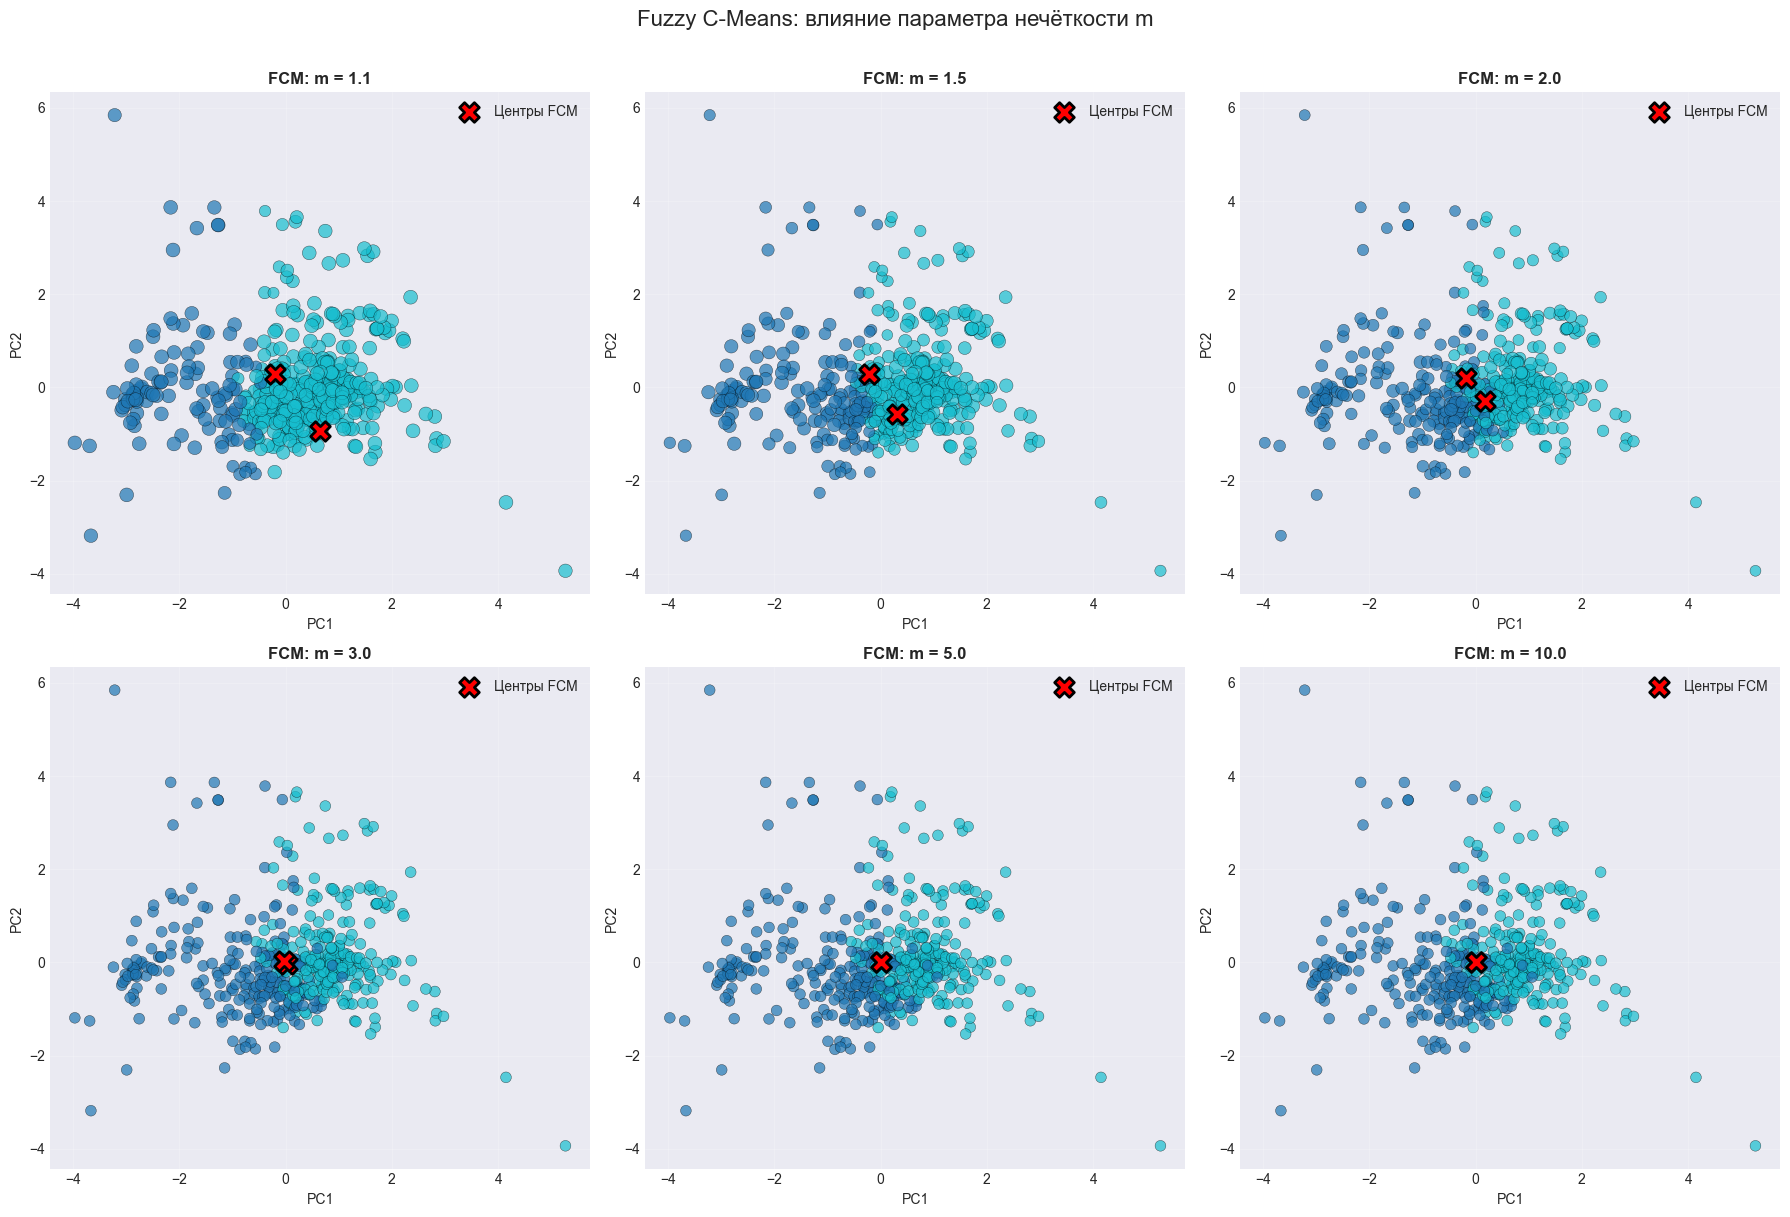

In [25]:
# PCA для визуализации (используем уже существующий X_pca)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, m in enumerate(m_values):
    u = fcm_results[m]['u']

    # Жёсткое назначение (по максимуму)
    hard_labels = np.argmax(u, axis=1)
    # Уверенность (макс. степень принадлежности)
    confidence = u.max(axis=1)

    # Визуализация: цвет — кластер, размер точки — уверенность
    scatter = axes[idx].scatter(
        X_pca[:, 0], X_pca[:, 1],
        c=hard_labels,
        s=20 + 80 * confidence,  # размер тем больше, чем выше уверенность
        cmap='tab10',
        alpha=0.7,
        edgecolors='k',
        linewidth=0.3
    )
    # Добавляем центры кластеров (в PCA-пространстве)
    centers_pca = fcm_results[m]['centers']
    axes[idx].scatter(centers_pca[:, 0], centers_pca[:, 1],
                      marker='X', s=200, c='red', edgecolors='black', linewidth=2,
                      label='Центры FCM')

    axes[idx].set_title(f'FCM: m = {m:.1f}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('PC1')
    axes[idx].set_ylabel('PC2')
    axes[idx].legend(loc='best')
    axes[idx].grid(True, alpha=0.2)

plt.suptitle('Fuzzy C-Means: влияние параметра нечёткости m', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()


In [26]:
from sklearn.cluster import KMeans

# Получаем центры k-means
kmeans_euclidean = KMeans(n_clusters=k_optimal, init='k-means++', random_state=42, n_init=10)
kmeans_euclidean.fit(X_scaled)
kmeans_centers = kmeans_euclidean.cluster_centers_

# Находим индексы точек, ближайших к центрам k-means
center_indices = []
for center in kmeans_centers:
    dist = np.sqrt(np.sum((X_scaled - center) ** 2, axis=1))
    center_indices.append(np.argmin(dist))

print(f"Индексы точек-центров (k-means): {center_indices}")

# Выбираем граничные точки: точки с минимальной разницей между двумя наибольшими
# степенями принадлежности (при m=2.0 — стандартный FCM)
u_m2 = fcm_results[2.0]['u']
sorted_u = np.sort(u_m2, axis=1)  # сортировка по возрастанию
diff_top2 = sorted_u[:, -1] - sorted_u[:, -2]  # разница между 1-м и 2-м местом

# Индексы с наименьшей разницей (самые «неуверенные» точки)
border_count = 4
border_indices = np.argsort(diff_top2)[:border_count]

print(f"Индексы граничных точек (min разница между top-2): {border_indices}")

# Объединяем индексы
selected_indices = np.concatenate([center_indices, border_indices])
selected_indices = np.unique(selected_indices)  # на случай дублирования

print(f"\nВыбрано точек для анализа: {len(selected_indices)}")
print(f"Итоговые индексы: {selected_indices}")

Индексы точек-центров (k-means): [369, 331]
Индексы граничных точек (min разница между top-2): [131 422 181 354]

Выбрано точек для анализа: 6
Итоговые индексы: [131 181 331 354 369 422]
